# Linear Regression Model Variants

Train a linear regression model that maps movement features to expert scores, trying different variants:
- Baseline
- Feature selection (p-value based removal)
- Combined features (interaction term)
- Outlier removal (studentized residuals)
- Weighted Least Squares

Assess accuracy using R², RMSE, MAE and select a champion model.

In [7]:
import os
import sys

# include root in project path
project_root = os.path.abspath("../..")
if project_root not in sys.path:
    sys.path.append(project_root)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import statsmodels.api as sm

from mlflow.models import infer_signature
import mlflow

from dotenv import load_dotenv

import src.mlflow.mlflow_utils as ml_utils


import warnings
from urllib3.exceptions import InsecureRequestWarning
warnings.filterwarnings("ignore", category=InsecureRequestWarning)

print(os.getcwd())


/Users/pettergustafsson/study/4DT907/ml_project/machine_learning_project_4dt907/ml/models/research/A2


In [3]:
# load environmental resources
load_dotenv("../../ml.env")

True

In [10]:
# training function
def linear_model_trainer(X_train, X_test, y_train, y_test):
    model = LinearRegression()
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    input_example = X_train[:5]

    signature = infer_signature(X_train, y_train_pred)
    
    return {
        'model': model,
        "metrics": {
            'train_r2': r2_score(y_train, y_train_pred),
            'train_rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
            'train_mae': mean_absolute_error(y_train, y_train_pred),
            'test_r2': r2_score(y_test, y_test_pred),
            'test_rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
            'test_mae': mean_absolute_error(y_test, y_test_pred),
        },
        "params": {
            "model": "LinearRegression"
        },
        "input_example": input_example,
        "signature": signature
    }

## 1. Load Data

In [11]:
df = pd.read_csv('../../data/processed/AimoScore_WeakLink_big_scores.csv')
print(f"Dataset: {df.shape[0]} samples, {df.shape[1]} columns")

X = df.drop(columns=['AimoScore', 'EstimatedScore', 'ID'])
y = df['AimoScore']

print(f"Features: {X.shape[1]}")
print(f"Target range: {y.min():.2f} - {y.max():.2f}")

Dataset: 2094 samples, 43 columns
Features: 40
Target range: 0.01 - 0.99


## 2. Train/Test Split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training: {X_train.shape[0]} samples")
print(f"Test:     {X_test.shape[0]} samples")

# Store all results for comparison
results = {}

Training: 1675 samples
Test:     419 samples


## 3. Train and register Baseline model

In [13]:
# train outside run_and_register_mlflow and use the function to register instead
train_results = linear_model_trainer(X_train, X_test, y_train, y_test)

experiment_name = "A2_linear_regression"
run_results = ml_utils.run_and_register_mlflow(
    experiment_name=experiment_name,
    run_name="baseline_model",

    params=train_results["params"],
    metrics=train_results["metrics"],
    model=train_results["model"],
    flavor=mlflow.sklearn.log_model,
    flavor_kwargs={
        "input_example": train_results["input_example"],
        "signature": train_results["signature"],
    },
    tracking_uri=os.getenv("MLFLOW_TRACKING_URI"),
)


/Users/pettergustafsson/study/4DT907/ml_project/machine_learning_project_4dt907/ml/models/venv/lib/python3.11/site-packages/mlflow/models/model.py:1209: FutureWarning: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization.The recommended safe alternative is the 'skops' format.
  flavor.save_model(path=local_path, mlflow_model=mlflow_model, **kwargs)


🏃 View run baseline_model at: https://172.27.62.170:5001/#/experiments/17/runs/0ad7ff3886ff4f6586149aa35220e95f
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/17


In [14]:
# Add results

results["Baseline"] = train_results["metrics"]

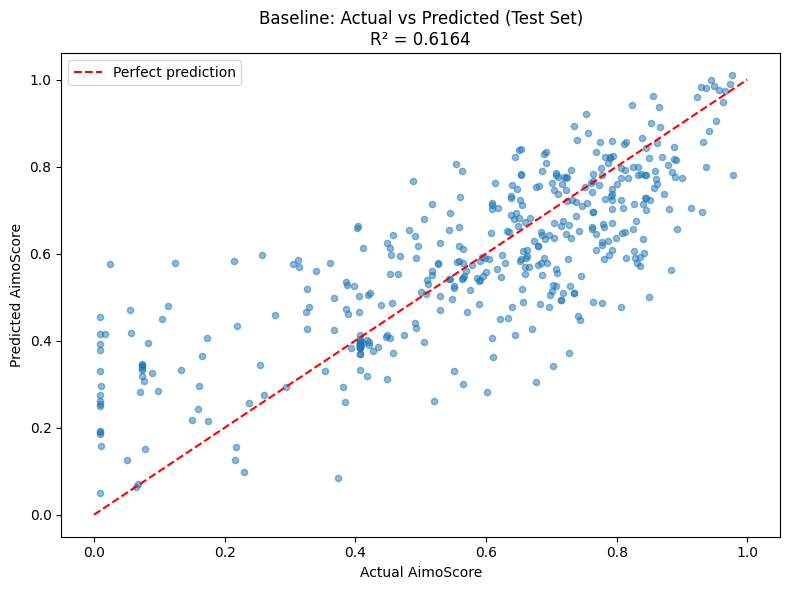

In [15]:
# Plot: Actual vs Predicted for baseline
baseline = train_results["model"]
pred = baseline.predict(X_test)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, pred, alpha=0.5, s=20)
plt.plot([0, 1], [0, 1], 'r--', label='Perfect prediction')
plt.xlabel('Actual AimoScore')
plt.ylabel('Predicted AimoScore')
plt.title(f"Baseline: Actual vs Predicted (Test Set)\nR² = {train_results['metrics']['test_r2']:.4f}")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Feature Selection (p-value based)

Remove features where the coefficient is not statistically significant (p > 0.05).

In [16]:
# Fit OLS with statsmodels to get p-values
X_train_const = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_const).fit()

# Get p-values for each feature (exclude constant)
pvalues = ols_model.pvalues[1:]  # skip the constant term

# Select features with p-value < 0.05
significant_features = pvalues[pvalues < 0.05].index.tolist()
removed_features = pvalues[pvalues >= 0.05].index.tolist()

print(f"Significant features (p < 0.05): {len(significant_features)}/{len(pvalues)}")
print(f"Removed features: {removed_features}")

Significant features (p < 0.05): 20/40
Removed features: ['No_2_Angle_Deviation', 'No_4_Angle_Deviation', 'No_7_Angle_Deviation', 'No_10_Angle_Deviation', 'No_13_Angle_Deviation', 'No_2_NASM_Deviation', 'No_4_NASM_Deviation', 'No_5_NASM_Deviation', 'No_7_NASM_Deviation', 'No_11_NASM_Deviation', 'No_13_NASM_Deviation', 'No_14_NASM_Deviation', 'No_16_NASM_Deviation', 'No_18_NASM_Deviation', 'No_20_NASM_Deviation', 'No_21_NASM_Deviation', 'No_23_NASM_Deviation', 'No_25_NASM_Deviation', 'No_1_Time_Deviation', 'No_2_Time_Deviation']


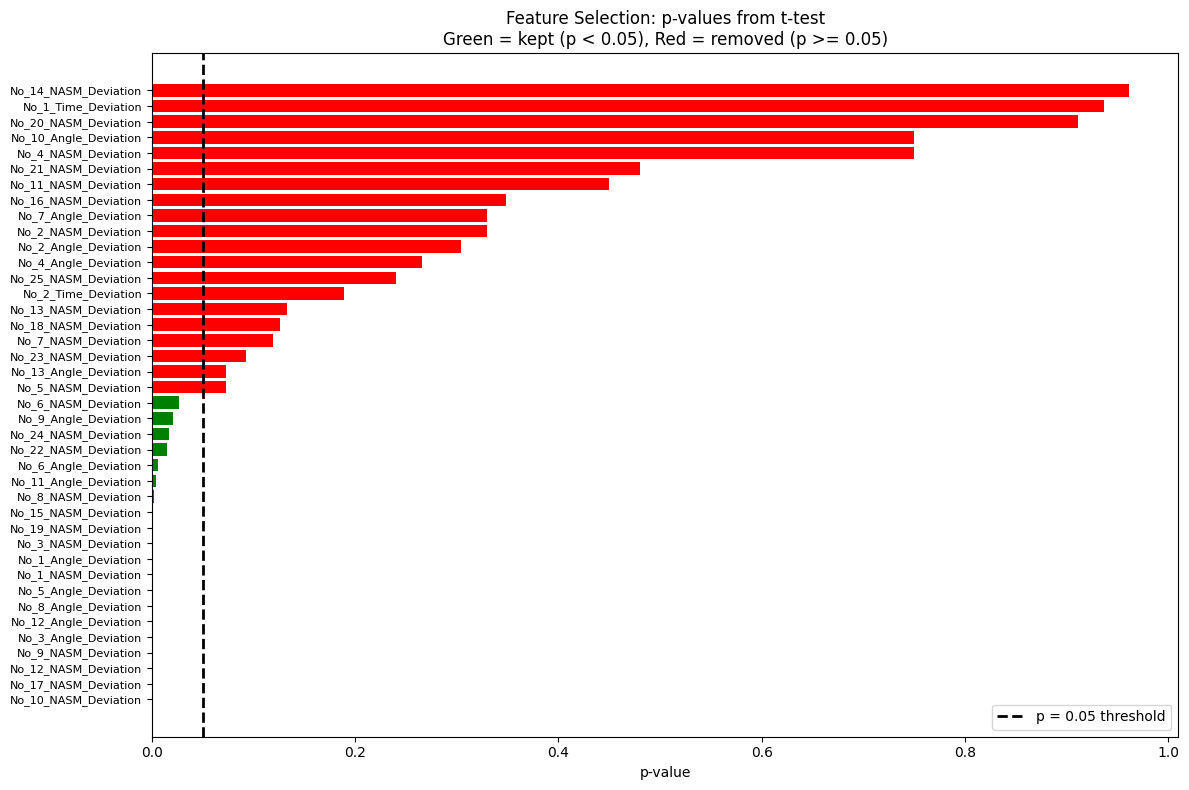


Kept 20 features, removed 20 features


In [17]:
# Plot p-values for all features
pvalues_sorted = pvalues.sort_values()

plt.figure(figsize=(12, 8))
colors = ['green' if p < 0.05 else 'red' for p in pvalues_sorted.values]
bars = plt.barh(range(len(pvalues_sorted)), pvalues_sorted.values, color=colors)
plt.yticks(range(len(pvalues_sorted)), pvalues_sorted.index, fontsize=8)
plt.axvline(x=0.05, color='black', linestyle='--', linewidth=2, label='p = 0.05 threshold')
plt.xlabel('p-value')
plt.title('Feature Selection: p-values from t-test\nGreen = kept (p < 0.05), Red = removed (p >= 0.05)')
plt.legend()
plt.tight_layout()
plt.show()

print(f"\nKept {len(significant_features)} features, removed {len(removed_features)} features")

In [18]:
# Train model with only significant features
X_train_sig = X_train[significant_features]
X_test_sig = X_test[significant_features]

train_results = linear_model_trainer(X_train_sig, X_test_sig, y_train, y_test)

ml_utils.run_and_register_mlflow(
    run_name="feature_selection_model",

    params=train_results["params"],
    metrics=train_results["metrics"],
    model=train_results["model"],
    flavor=mlflow.sklearn.log_model,
    flavor_kwargs={
        "input_example": train_results["input_example"],
        "signature": train_results["signature"],
    },
)


/Users/pettergustafsson/study/4DT907/ml_project/machine_learning_project_4dt907/ml/models/venv/lib/python3.11/site-packages/mlflow/models/model.py:1209: FutureWarning: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization.The recommended safe alternative is the 'skops' format.
  flavor.save_model(path=local_path, mlflow_model=mlflow_model, **kwargs)


🏃 View run feature_selection_model at: https://172.27.62.170:5001/#/experiments/17/runs/fe14e1f5d8e24911b521c5ba9034a6c7
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/17


{'run_id': 'fe14e1f5d8e24911b521c5ba9034a6c7',
 'model_uri': 'models:/m-2492cf67332844708816501148259847',
 'registered_model_version': None}

In [19]:
results['Feature Selection (p-value)'] = train_results["metrics"]
print(f"Feature Selection: R²={results['Feature Selection (p-value)']['test_r2']:.4f}, RMSE={results['Feature Selection (p-value)']['test_rmse']:.4f}, MAE={results['Feature Selection (p-value)']['test_mae']:.4f}")

Feature Selection: R²=0.5977, RMSE=0.1550, MAE=0.1167


## 5. Combined Features (Interaction Term)

Add a single interaction term X_i · X_j between the two features most correlated with the target.

In [20]:
# Find the two features most correlated with the target
correlations = X_train.corrwith(y_train).abs().sort_values(ascending=False)
top_two = correlations.head(2).index.tolist()

print(f"Top 2 features correlated with target:")
print(f"  {top_two[0]}: r = {correlations[top_two[0]]:.4f}")
print(f"  {top_two[1]}: r = {correlations[top_two[1]]:.4f}")

Top 2 features correlated with target:
  No_12_NASM_Deviation: r = 0.4947
  No_11_NASM_Deviation: r = 0.4577


In [21]:
# Add interaction term
interaction_name = f"{top_two[0]}_x_{top_two[1]}"

X_train_int = X_train.copy()
X_train_int[interaction_name] = X_train[top_two[0]] * X_train[top_two[1]]

X_test_int = X_test.copy()
X_test_int[interaction_name] = X_test[top_two[0]] * X_test[top_two[1]]

print(f"Added interaction term: {interaction_name}")
print(f"Features: {X_train_int.shape[1]} (was {X_train.shape[1]})")

train_results = linear_model_trainer(X_train_int, X_test_int, y_train, y_test)

ml_utils.run_and_register_mlflow(
    run_name="interaction_term_model",

    params=train_results["params"],
    metrics=train_results["metrics"],
    model=train_results["model"],
    flavor=mlflow.sklearn.log_model,
    flavor_kwargs={
        "input_example": train_results["input_example"],
        "signature": train_results["signature"],
    },
)



Added interaction term: No_12_NASM_Deviation_x_No_11_NASM_Deviation
Features: 41 (was 40)


/Users/pettergustafsson/study/4DT907/ml_project/machine_learning_project_4dt907/ml/models/venv/lib/python3.11/site-packages/mlflow/models/model.py:1209: FutureWarning: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization.The recommended safe alternative is the 'skops' format.
  flavor.save_model(path=local_path, mlflow_model=mlflow_model, **kwargs)


🏃 View run interaction_term_model at: https://172.27.62.170:5001/#/experiments/17/runs/254e2dc1d28242d6b8e4a99be6307a53
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/17


In [22]:
results["Combined Features (Interaction)"] = train_results["metrics"]
print(f"Combined Features: R²={results['Combined Features (Interaction)']['test_r2']:.4f}, RMSE={results['Combined Features (Interaction)']['test_rmse']:.4f}, MAE={results['Combined Features (Interaction)']['test_mae']:.4f}")

Combined Features: R²=0.6412, RMSE=0.1464, MAE=0.1112


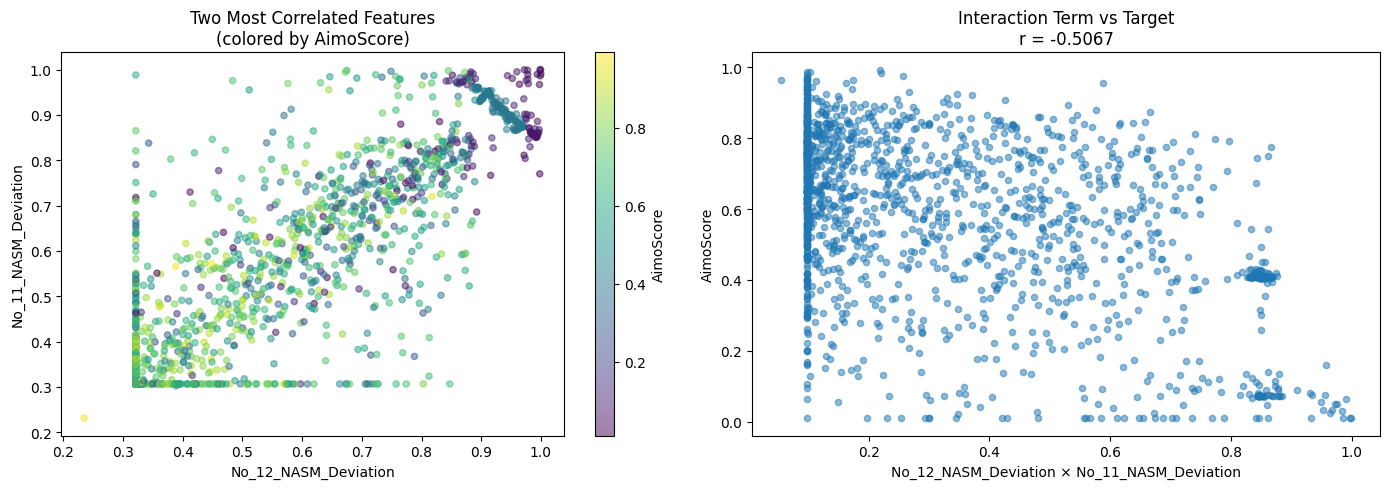

In [23]:
# Plot: Interaction effect visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Scatter of the two features colored by target
ax = axes[0]
scatter = ax.scatter(X_train[top_two[0]], X_train[top_two[1]], c=y_train, cmap='viridis', alpha=0.5, s=20)
plt.colorbar(scatter, ax=ax, label='AimoScore')
ax.set_xlabel(top_two[0])
ax.set_ylabel(top_two[1])
ax.set_title('Two Most Correlated Features\n(colored by AimoScore)')

# Right: Interaction term vs target
ax = axes[1]
interaction_values = X_train[top_two[0]] * X_train[top_two[1]]
ax.scatter(interaction_values, y_train, alpha=0.5, s=20)
ax.set_xlabel(f'{top_two[0]} × {top_two[1]}')
ax.set_ylabel('AimoScore')
ax.set_title(f'Interaction Term vs Target\nr = {np.corrcoef(interaction_values, y_train)[0,1]:.4f}')

plt.tight_layout()
plt.show()

## 6. Outlier Removal (Studentized Residuals)

Remove training points with |studentized residual| > 2.

In [24]:
# Fit OLS to get studentized residuals
X_train_const = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_const).fit()

# Get studentized residuals (externally studentized / deleted residuals)
influence = ols_model.get_influence()
studentized_resid = influence.resid_studentized_external

# Identify outliers
threshold = 2
outlier_mask = np.abs(studentized_resid) > threshold
n_outliers = outlier_mask.sum()

print(f"Studentized residual threshold: |r| > {threshold}")
print(f"Outliers identified: {n_outliers} ({100*n_outliers/len(y_train):.1f}%)")

Studentized residual threshold: |r| > 2
Outliers identified: 83 (5.0%)


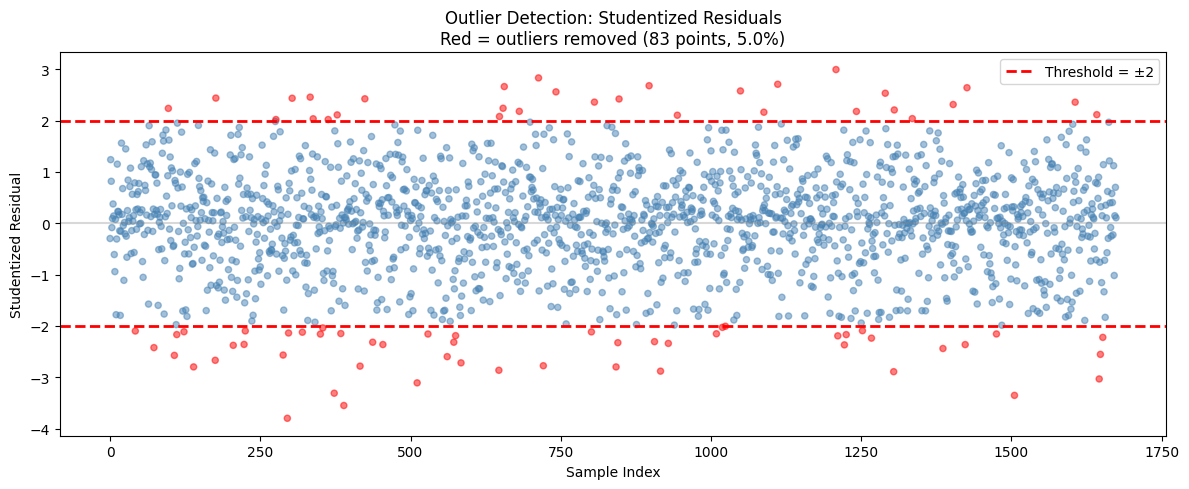

In [25]:
# Plot: Studentized residuals with outliers highlighted
plt.figure(figsize=(12, 5))

colors = np.where(outlier_mask, 'red', 'steelblue')
plt.scatter(range(len(studentized_resid)), studentized_resid, c=colors, alpha=0.5, s=20)
plt.axhline(y=threshold, color='red', linestyle='--', linewidth=2, label=f'Threshold = ±{threshold}')
plt.axhline(y=-threshold, color='red', linestyle='--', linewidth=2)
plt.axhline(y=0, color='gray', linestyle='-', alpha=0.3)
plt.xlabel('Sample Index')
plt.ylabel('Studentized Residual')
plt.title(f'Outlier Detection: Studentized Residuals\nRed = outliers removed ({n_outliers} points, {100*n_outliers/len(y_train):.1f}%)')
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
# Remove outliers from training set
X_train_clean = X_train[~outlier_mask]
y_train_clean = y_train[~outlier_mask]

print(f"Training samples after removal: {len(y_train_clean)} (was {len(y_train)})")

train_results = linear_model_trainer(X_train_clean, X_test, y_train_clean, y_test)

run_results = ml_utils.run_and_register_mlflow(
    run_name="outliar_removal_model",

    params=train_results["params"],
    metrics=train_results["metrics"],
    model=train_results["model"],
    flavor=mlflow.sklearn.log_model,
    flavor_kwargs={
        "input_example": train_results["input_example"],
        "signature": train_results["signature"],
    },
)

Training samples after removal: 1592 (was 1675)


/Users/pettergustafsson/study/4DT907/ml_project/machine_learning_project_4dt907/ml/models/venv/lib/python3.11/site-packages/mlflow/models/model.py:1209: FutureWarning: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization.The recommended safe alternative is the 'skops' format.
  flavor.save_model(path=local_path, mlflow_model=mlflow_model, **kwargs)


🏃 View run outliar_removal_model at: https://172.27.62.170:5001/#/experiments/17/runs/8ae0b5056a8a4a97bd7ba5325b5674dc
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/17


In [27]:
results['Outlier Removal (Studentized)'] = train_results["metrics"]

print(f"Outlier Removal: R²={results['Outlier Removal (Studentized)']['test_r2']:.4f}, RMSE={results['Outlier Removal (Studentized)']['test_rmse']:.4f}, MAE={results['Outlier Removal (Studentized)']['test_mae']:.4f}")

Outlier Removal: R²=0.6153, RMSE=0.1516, MAE=0.1137


## 7. Weighted Least Squares (WLS)

Give different weights to samples based on estimated variance. Samples with smaller residuals get higher weights.

In [28]:
# Step 1: Fit initial OLS model
initial_model = LinearRegression()
initial_model.fit(X_train, y_train)
y_train_pred_initial = initial_model.predict(X_train)

# Step 2: Compute residuals
residuals = y_train - y_train_pred_initial

# Step 3: Estimate weights as inverse of squared residuals
# Add small constant to avoid division by zero
epsilon = 1e-6
weights = 1 / (residuals**2 + epsilon)

# Normalize weights to sum to n
weights = weights / weights.sum() * len(weights)

print(f"Residuals: min={residuals.min():.4f}, max={residuals.max():.4f}")
print(f"Weights: min={weights.min():.4f}, max={weights.max():.4f}")

Residuals: min=-0.5736, max=0.4541
Weights: min=0.0002, max=76.2401


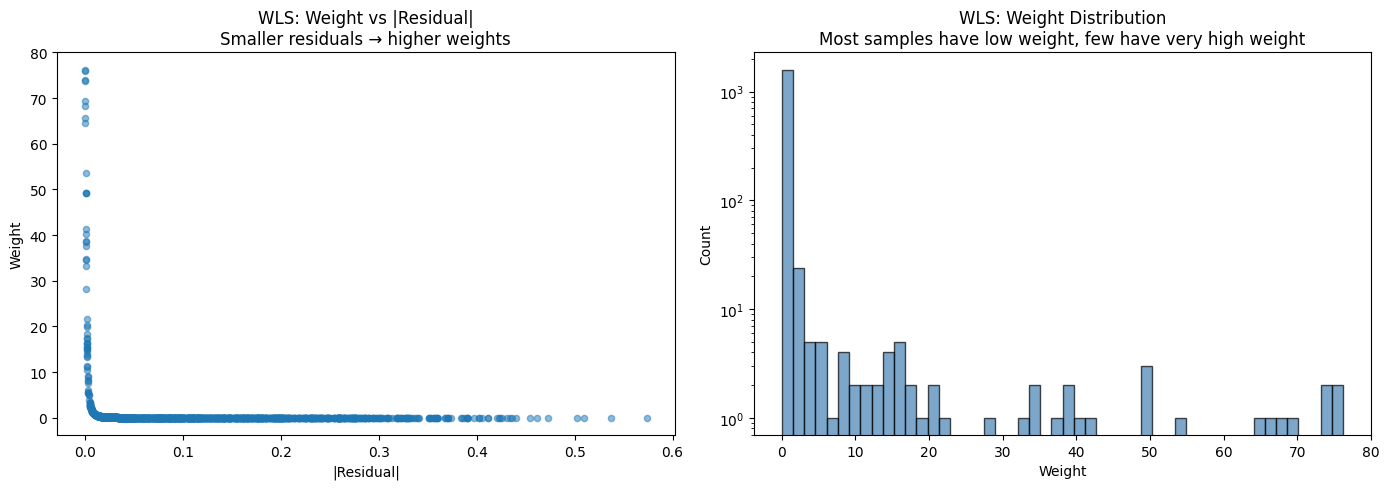

In [29]:
# Plot: WLS - Residuals vs Weights
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Residuals vs Weights
ax = axes[0]
ax.scatter(np.abs(residuals), weights, alpha=0.5, s=20)
ax.set_xlabel('|Residual|')
ax.set_ylabel('Weight')
ax.set_title('WLS: Weight vs |Residual|\nSmaller residuals → higher weights')

# Right: Weight distribution (histogram)
ax = axes[1]
ax.hist(weights, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Weight')
ax.set_ylabel('Count')
ax.set_title(f'WLS: Weight Distribution\nMost samples have low weight, few have very high weight')
ax.set_yscale('log')

plt.tight_layout()
plt.show()

In [30]:
# Step 4: Fit weighted model
wls_model = LinearRegression()
wls_model.fit(X_train, y_train, sample_weight=weights)

# Evaluate on train and test
y_train_pred = wls_model.predict(X_train)
y_test_pred = wls_model.predict(X_test)

input_example = X_train[:5]
signature = infer_signature(X_train, y_train_pred)


results['Weighted Least Squares'] = {
    'train_r2': r2_score(y_train, y_train_pred),
    'train_rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
    'train_mae': mean_absolute_error(y_train, y_train_pred),
    'test_r2': r2_score(y_test, y_test_pred),
    'test_rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
    'test_mae': mean_absolute_error(y_test, y_test_pred),
}

ml_utils.run_and_register_mlflow(
    run_name="weighted_model",

    params={"model": "LinearRegression"},
    metrics=results['Weighted Least Squares'],
    model=wls_model,
    flavor=mlflow.sklearn.log_model,
    flavor_kwargs={
        "input_example": input_example,
        "signature": signature,
    },
)



/Users/pettergustafsson/study/4DT907/ml_project/machine_learning_project_4dt907/ml/models/venv/lib/python3.11/site-packages/mlflow/models/model.py:1209: FutureWarning: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization.The recommended safe alternative is the 'skops' format.
  flavor.save_model(path=local_path, mlflow_model=mlflow_model, **kwargs)


🏃 View run weighted_model at: https://172.27.62.170:5001/#/experiments/17/runs/e3760caeadcf49559300d231d75950d1
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/17


{'run_id': 'e3760caeadcf49559300d231d75950d1',
 'model_uri': 'models:/m-40bcd74f7ef3454082fe395f42d1cc60',
 'registered_model_version': None}

In [31]:
print(f"Weighted Least Squares: R²={results['Weighted Least Squares']['test_r2']:.4f}, RMSE={results['Weighted Least Squares']['test_rmse']:.4f}, MAE={results['Weighted Least Squares']['test_mae']:.4f}")

Weighted Least Squares: R²=0.6164, RMSE=0.1513, MAE=0.1149


## 8. Model Comparison

In [32]:
print('=' * 80)
print(f'{"Model":<35s} {"Test R²":<12s} {"Test RMSE":<12s} {"Test MAE":<12s}')
print('-' * 80)
for name, m in results.items():
    print(f'{name:<35s} {m["test_r2"]:<12.4f} {m["test_rmse"]:<12.4f} {m["test_mae"]:<12.4f}')
print('=' * 80)

# Select champion (best test R²)
champion_name = max(results.keys(), key=lambda k: results[k]['test_r2'])
print(f"\nChampion: {champion_name}")
print(f"  R²   = {results[champion_name]['test_r2']:.4f}")
print(f"  RMSE = {results[champion_name]['test_rmse']:.4f}")
print(f"  MAE  = {results[champion_name]['test_mae']:.4f}")

Model                               Test R²      Test RMSE    Test MAE    
--------------------------------------------------------------------------------
Baseline                            0.6164       0.1513       0.1150      
Feature Selection (p-value)         0.5977       0.1550       0.1167      
Combined Features (Interaction)     0.6412       0.1464       0.1112      
Outlier Removal (Studentized)       0.6153       0.1516       0.1137      
Weighted Least Squares              0.6164       0.1513       0.1149      

Champion: Combined Features (Interaction)
  R²   = 0.6412
  RMSE = 0.1464
  MAE  = 0.1112
